# Lecture 11, Heat transports

> Two-dimensional advection-diffusion of heat


In [1]:
# Google Colab setup: install the packages this notebook uses.
# Runs only on Colab; skipped in Binder or a local Jupyter install.
import sys
if "google.colab" in sys.modules:
    %pip install -q numpy pandas matplotlib scipy xarray netcdf4 pydap ipywidgets


In [2]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets

from IPython.display import HTML
from IPython.display import display

# 1) Background: two-dimensional advection-diffusion

## 1.1) The two-dimensional advection-diffusion equation
Recall from **Lecture 9** that the one-dimensional advection-diffusion equation is written as

$$\frac{\partial T(x,t)}{\partial t} = -U \frac{\partial T}{\partial x} + \kappa \frac{\partial^{2} T}{\partial x^{2}},$$

where $T(x, t)$ is the temperature, $U$ is a constant advective velocity and $\kappa$ is the diffusivity.

The two-dimensional advection-diffusion equation simply adds advection and diffusion operators acting in a second dimension $y$ (orthogonal to $x$):

$$\frac{\partial T(x,y,t)}{\partial t} = - u(x,y) \frac{\partial T}{\partial x} - v(x,y) \frac{\partial T}{\partial y} + \kappa \left( \frac{\partial^{2} T}{\partial x^{2}} + \frac{\partial^{2} T}{\partial y^{2}} \right),$$

where $\vec{u}(x,y) = (u, v) = u\,\mathbf{\hat{x}} + v\,\mathbf{\hat{y}}$ is a velocity vector field.

Throughout the rest of the Climate Modelling module, we will consider $x$ to be the *longitudinal* direction (positive from west to east) and $y$ to be the *latitudinal* direction (positive from south to north).

## 1.2) Flux form, shorthand notation, and the advective form

Conventionally, the two-dimensional advection-diffusion equation is written more succinctly in its **flux form** (also called the *conservation form*):

$$\frac{\partial T(x,y,t)}{\partial t} = - \nabla \cdot (\vec{u}\,T) + \kappa \nabla^{2} T,$$

using the following shorthand notation.

The **gradient** operator is defined as

$$\nabla \equiv \left(\frac{\partial}{\partial x}, \frac{\partial }{\partial y}\right)$$

such that

$$\nabla T = \left(\frac{\partial T}{\partial x}, \frac{\partial T}{\partial y}\right).$$

The **Laplacian** operator $\nabla^{2}$ (sometimes denoted $\Delta$) is defined as

$$\nabla^{2} = \frac{\partial^{2}}{\partial x^{2}} + \frac{\partial^{2}}{\partial y^{2}}$$

such that

$$\nabla^{2} T = \frac{\partial^{2} T}{\partial x^{2}} + \frac{\partial^{2} T}{\partial y^{2}}.$$

The **divergence** operator is defined as $\nabla \cdot [\quad]$, such that for a vector field $(a, b)$

$$\nabla \cdot (a, b) = \left(\frac{\partial}{\partial x}, \frac{\partial}{\partial y} \right) \cdot (a, b) = \frac{\partial a}{\partial x} + \frac{\partial b}{\partial y}.$$

In particular, the divergence of the advective flux $\vec{u}\,T = (uT, vT)$ is

$$\nabla \cdot (\vec{u}\,T) = \frac{\partial (uT)}{\partial x} + \frac{\partial (vT)}{\partial y},$$

and the divergence of the velocity itself is $\nabla \cdot \vec{u} = \dfrac{\partial u}{\partial x} + \dfrac{\partial v}{\partial y}$.

The flux form has a clear physical meaning: $\vec{u}\,T$ is the flux of temperature carried by the flow and $-\kappa \nabla T$ is the flux by diffusion, so $T$ in a cell changes only because of the net flux through its edges.

### From the flux form to the advective form

**Note:** Since seawater is largely incompressible, we can approximate ocean currents as a *non-divergent flow*, with $\nabla \cdot \vec{u} = \frac{\partial u}{\partial x} + \frac{\partial v}{\partial y} = 0$. Among other implications, this lets us start from the advective term of the flux form, $\nabla \cdot (\vec{u}\,T)$, and reach the more familiar form $\vec{u} \cdot \nabla T$:

$$
\begin{aligned}
\nabla \cdot (\vec{u}\,T) &= \frac{\partial (uT)}{\partial x} + \frac{\partial (vT)}{\partial y} \\
&= \left( u\frac{\partial T}{\partial x} + T\frac{\partial u}{\partial x} \right) + \left( v\frac{\partial T}{\partial y} + T\frac{\partial v}{\partial y} \right) \\
&= u\frac{\partial T}{\partial x} + v\frac{\partial T}{\partial y} + T\left(\frac{\partial u}{\partial x} + \frac{\partial v}{\partial y}\right) \\
&= \vec{u} \cdot \nabla T + T\,\nabla \cdot \vec{u} \\
&= \vec{u} \cdot \nabla T,
\end{aligned}
$$

where the second line uses the product rule (separately in both $x$ and $y$), the fourth line uses

$$\vec{u} \cdot \nabla T = (u, v) \cdot \left(\frac{\partial T}{\partial x}, \frac{\partial T}{\partial y}\right) = u \frac{\partial T}{\partial x} + v\frac{\partial T}{\partial y},$$

and the last line uses $\nabla \cdot \vec{u} = 0$.

This lets us finally re-write the two-dimensional advection-diffusion equation in its **advective form**:

$$\frac{\partial T}{\partial t} = - \vec{u} \cdot \nabla T + \kappa \nabla^{2} T = - u\frac{\partial T}{\partial x} - v\frac{\partial T}{\partial y} + \kappa \left( \frac{\partial^{2} T}{\partial x^{2}} + \frac{\partial^{2} T}{\partial y^{2}} \right),$$

which is the same as the equation of Section 1.1, and the form we will use in our numerical algorithm below.

# 2) Numerical implementation

# 2.1) Discretizing advection in two dimensions

In Lecture 9 we saw that in one dimension we can discretize a first-partial derivative in space using the *centered finite difference*

$$\frac{\partial T(x_{i}, t_{n})}{\partial x} \approx \frac{T_{i+1}^{n} - T_{i-1}^{n}}{2 \Delta x}.$$

In two dimensions, we discretize the partial derivative the exact same way, except that we also need to keep track of the cell index $j$ in the $y$ dimension:

$$\frac{\partial T(x_{i}, y_{j}, t_{n})}{\partial x} \approx \frac{T_{i+1,\, j}^{n} - T_{i-1,\,j}^{n}}{2 \Delta x}.$$

The *x-gradient kernel* below, is shown below, and is reminiscent of the *edge-detection* or *sharpening* kernels used in image processing and machine learning:

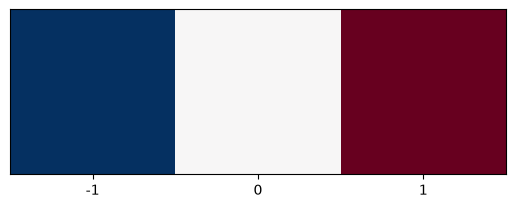

In [3]:
plt.imshow([[-1,0,1]], cmap=plt.cm.RdBu_r)
plt.xticks([0,1,2], labels=[-1,0,1]);
plt.yticks([]);

The first-order partial derivative in $y$ is similarly discretized as:

$$\frac{\partial T(x_{i}, y_{j}, t_{n})}{\partial y} \approx \frac{T_{i,\, j+1}^{n} - T_{i,\,j-1}^{n}}{2 \Delta y}.$$

Its kernel is shown below (row $j+1$ lies to the north, so it is drawn at the top).

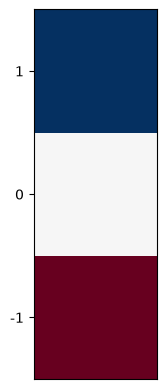

In [4]:
plt.imshow([[1], [0], [-1]], cmap=plt.cm.RdBu)
plt.xticks([])
plt.yticks([0, 1, 2], labels=[1, 0, -1]);

Now that we have discretized the two derivative terms, we can write out the *advective tendency* for computing $T_{i,\, j}^{n+1}$ as

$$-\left(u\frac{\partial T}{\partial x} + v\frac{\partial T}{\partial y}\right) \approx -\left( u_{i,\, j} \frac{T_{i+1,\, j}^{n} - T_{i-1,\,j}^{n}}{2 \Delta x} + v_{i,\, j} \frac{T_{i,\, j+1}^{n} - T_{i,\,j-1}^{n}}{2 \Delta y} \right).$$

We implement this as the `advect` function. It computes the advective tendency of every interior grid cell $(i,j)$ by sliding the two kernels over the temperature field.

In [5]:
xkernel = np.zeros((1,3))
xkernel[0, :] = np.array([-1,0,1])

In [6]:
ykernel = np.zeros((3,1))
ykernel[:, 0] = np.array([-1,0,1])

In [7]:
def advect(T, u, v, deltax, deltay):
    """Advective tendency  -(u dT/dx + v dT/dy)  of the interior cells."""
    T_advect = np.zeros_like(T)
    for j in range(1, T.shape[0] - 1):
        for i in range(1, T.shape[1] - 1):
            dTdx = np.sum(xkernel[0, :] * T[j, i-1:i+2]) / (2 * deltax)
            dTdy = np.sum(ykernel[:, 0] * T[j-1:j+2, i]) / (2 * deltay)
            T_advect[j, i] = -(u[j, i] * dTdx + v[j, i] * dTdy)
    return T_advect

## 2.2) Discretizing diffusion in two dimensions

Just as with advection, the process for discretizing the diffusion operators effectively consists of repeating the one-dimensional process for $x$ in a second dimension $y$, separately:

$$\kappa \left( \frac{\partial^{2} T}{\partial x^{2}} + \frac{\partial^{2} T}{\partial y^{2}} \right) = \kappa \left(
\frac{T_{i+1,\;j}^{n} - 2T_{i,\;j}^{n} + T_{i-1,\;j}^{n}}{\left( \Delta x \right)^{2}} +
\frac{T_{i,\;j+1}^{n} - 2T_{i,\;j}^{n} + T_{i,\;j-1}^{n}}{\left( \Delta y \right)^{2}}
\right)$$

The corresponding $x$ and $y$ second-derivative kernels are shown below:

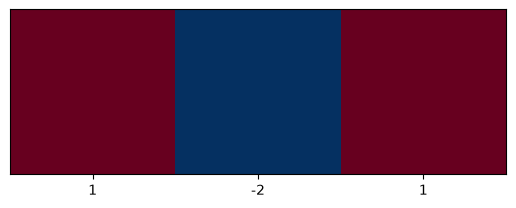

In [8]:
plt.imshow([[1, -2, 1]], cmap=plt.cm.RdBu_r)
plt.xticks([0, 1, 2], labels=[1, -2, 1])
plt.yticks([]);

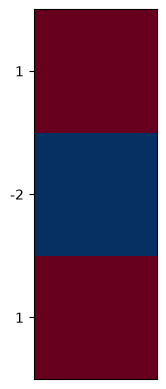

In [9]:
plt.imshow([[1], [-2], [1]], cmap=plt.cm.RdBu_r)
plt.xticks([])
plt.yticks([0, 1, 2], labels=[1, -2, 1]);

In [10]:
xkernel_diff = np.zeros((1, 3))
xkernel_diff[0, :] = np.array([1,-2,1])

In [11]:
ykernel_diff = np.zeros((3,1))
ykernel_diff[:, 0] = np.array([1,-2,1])

Just as we did with advection, we implement a `diffuse` function that slides these kernels over the temperature field:

In [12]:
def diffuse(T, kappa, deltax, deltay):
    """Diffusive tendency  kappa (d2T/dx2 + d2T/dy2)  of the interior cells."""
    T_diffuse = np.zeros_like(T)
    for j in range(1, T.shape[0] - 1):
        for i in range(1, T.shape[1] - 1):
            d2Tdx2 = np.sum(xkernel_diff[0, :] * T[j, i-1:i+2]) / deltax**2
            d2Tdy2 = np.sum(ykernel_diff[:, 0] * T[j-1:j+2, i]) / deltay**2
            T_diffuse[j, i] = kappa * (d2Tdx2 + d2Tdy2)
    return T_diffuse

## 2.3) No-flux boundary conditions

The ocean basin has walls, so the total flux of temperature through each boundary must vanish:

$u\,T - \kappa\dfrac{\partial T}{\partial x} = 0$ at the $x$ boundaries and

$v\,T - \kappa\dfrac{\partial T}{\partial y} = 0$ at the $y$ boundaries.

The flow itself does not cross a wall ($u = 0$ at the $x$ boundaries and $v = 0$ at the $y$ boundaries), so these conditions reduce to $\partial T/\partial x = 0$ and $\partial T/\partial y = 0$ there.

To impose this, we surround the basin with a ring of *ghost cells* (the outermost rows and columns of the array), which do not represent ocean but help us impose the boundary conditions. Discretely, the boundary flux between the first column (the ghost cell, $i=1$) and the second column ($i=2$) vanishes if

$\dfrac{T_{2,\,j}^{n} -T_{1,\,j}^{n}}{\Delta x} = 0$ or

$T_{1,\,j}^{n} = T_{2,\,j}^{n}.$

Thus, we can implement the boundary conditions by updating the temperature of the ghost cells to match their interior-point neighbors:

In [13]:
def update_ghostcells(var):
    var[0, :] = var[1, :]
    var[-1, :] = var[-2, :]
    var[:, 0] = var[:, 1]
    var[:, -1] = var[:, -2]
    return var

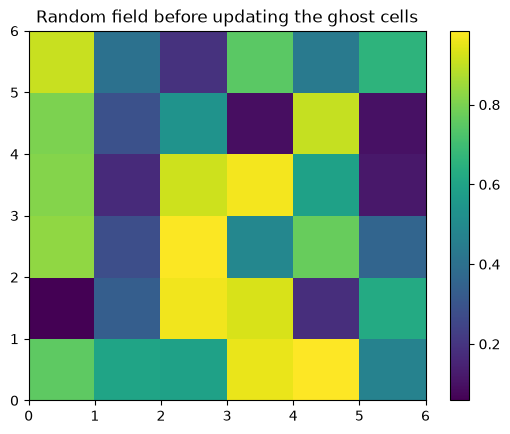

In [14]:
B = np.random.rand(6, 6)
plt.pcolor(B)
plt.colorbar()
plt.title("Random field before updating the ghost cells");

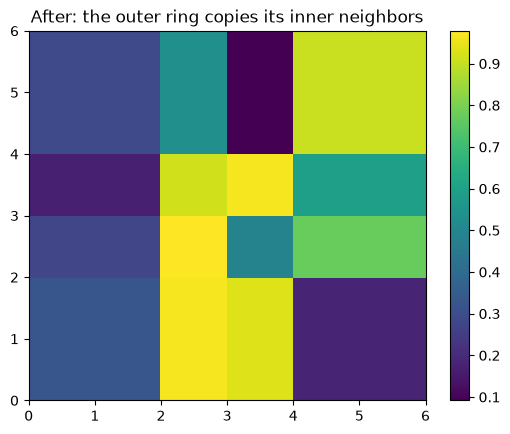

In [15]:
B = update_ghostcells(B)
plt.pcolor(B)
plt.colorbar()
plt.title("After: the outer ring copies its inner neighbors");

## 2.4) Timestepping

With the two tendencies and the boundary condition in hand, we march the temperature forward in time with the *forward Euler* scheme used in Lecture 9:

$$T_{i,j}^{n+1} = T_{i,j}^{n} + \Delta t \left[ \text{advect}(T^{n}) + \text{diffuse}(T^{n}) \right]_{i,j}.$$

At every step the ghost cells are updated **first**, so that the tendencies are computed from a field that already satisfies the no-flux condition, and once more after the step. We wrap the algorithm in an `OceanModel` class that stores the whole history of the temperature field.

In [16]:
class OceanModel:
    """Temperature in a closed ocean basin, advected by the wind-driven flow (u, v) and diffused by kappa."""

    def __init__(self, T, deltat, windfield, grid, kappa):
        self.T = [T.copy()]
        self.u = windfield.u
        self.v = windfield.v
        self.deltax = grid.deltax
        self.deltay = grid.deltay
        self.deltat = deltat
        self.kappa = kappa
        self.t = [0.0]

    def advect(self, T):
        return advect(T, self.u, self.v, self.deltax, self.deltay)

    def diffuse(self, T):
        return diffuse(T, self.kappa, self.deltax, self.deltay)

    def timestep(self):
        T = update_ghostcells(self.T[-1].copy())      # impose no-flux before computing the tendencies
        tendencies = self.advect(T) + self.diffuse(T)
        T_new = update_ghostcells(T + self.deltat * tendencies)
        self.T.append(T_new)
        self.t.append(self.t[-1] + self.deltat)

In [17]:
class grid:
    """Creates the grid of the ocean model.

    N: number of grid cells across the width of the basin (the basin is N x 2N cells)
    L: width of the basin [m]; its length is 2L (y runs from -L to L)
    """
    def __init__(self, N, L):
        self.N = N
        self.L = L
        self.deltax = L / N
        self.deltay = L / N
        # cell centers, including one ghost cell on every side
        self.xs = (np.arange(N + 2) - 0.5) * self.deltax
        self.ys = (np.arange(2 * N + 2) - 0.5) * self.deltay - L
        self.X, self.Y = np.meshgrid(self.xs, self.ys)
        self.grid = np.zeros(self.X.shape)
        self.Nx = len(self.xs)
        self.Ny = len(self.ys)


class windfield:
    """Wind-driven ocean flow.

    Args:
    ------
    grid: class grid()
    option: "zero" or "single_gyre"
    """

    def __init__(self, grid, option="zero"):
        if option == "zero":
            self.u = np.zeros(grid.grid.shape)
            self.v = np.zeros(grid.grid.shape)
        elif option == "single_gyre":
            self.u, self.v = single_gyre(grid)
        else:
            raise ValueError(option)

Initialize a $10 \times 20$ grid domain (10 cells across, 20 cells along) with $L=6000000$ m and a windfield where all velocities are set to zero.
This should result in diffusion only.

Initialize the temperature field with a rectangular non-zero box.

In [18]:
my_grid = grid(N = 10, L = 6e6)
my_wind = windfield(my_grid, option = "zero")
my_temp = np.zeros((my_grid.grid.shape))
my_temp[9:13, 4:8] = 1

In [19]:
my_grid.grid.shape

(22, 12)

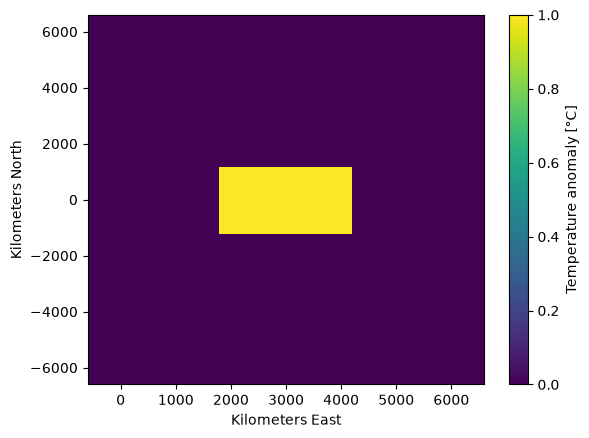

In [20]:
plt.pcolor(my_grid.xs / 1e3, my_grid.ys / 1e3, my_temp)
plt.colorbar(label = "Temperature anomaly [°C]")
plt.ylabel("Kilometers North")
plt.xlabel("Kilometers East");

In [21]:
deltat = 12*60*60 # 12 Hours

In [22]:
def plot_func(steps, temp, deltat, windfield, grid, kappa, anomaly = False):
    my_model = OceanModel(T=temp,
                      deltat=deltat,
                      windfield=windfield,
                      grid=grid,
                      kappa = kappa)
    for step in range(steps):
        my_model.timestep()
    plt.figure(figsize=(6,8))
    if anomaly == True:
        # change over the most recent time step
        m = plt.pcolormesh(grid.xs / 1e3, grid.ys / 1e3, my_model.T[-1] - my_model.T[-2], cmap = plt.cm.RdBu_r,
                  vmin = -0.001, vmax = 0.001, shading = "nearest")
        label = "Change per time step [°C]"
    else:
        m = plt.pcolormesh(grid.xs / 1e3, grid.ys / 1e3, my_model.T[-1], vmin = 0, vmax = 1, shading = "nearest")
        label = "Temperature anomaly [°C]"
    if np.any(windfield.u):
        plt.quiver(grid.X / 1e3, grid.Y / 1e3, windfield.u, windfield.v)
    plt.colorbar(m, label = label)
    plt.ylabel("Kilometers North")
    plt.xlabel("Kilometers East")
    plt.title("Time: {:.1f} days".format(my_model.t[-1] / 86400))
    plt.show()

In [23]:
interact(plot_func,
         temp = fixed(my_temp),
         deltat = fixed(deltat),
         windfield = fixed(my_wind),
         grid = fixed(my_grid),
         kappa = fixed(1e4),
         anomaly = widgets.Checkbox(description = "Anomaly", value=False),
         steps = widgets.IntSlider(description="Timesteps", value = 2, min = 1, max = 10000, step = 1));

interactive(children=(IntSlider(value=2, description='Timesteps', max=10000, min=1), Checkbox(value=False, des…

## Create a single-gyre windfield

The flow is derived from a *streamfunction* $\psi$ by $u = \partial \psi / \partial y$ and $v = -\partial \psi / \partial x$. Any flow defined this way is automatically non-divergent, $\partial u/\partial x + \partial v/\partial y = 0$, as assumed in Section 1.2.

The walls of the basin must also be impermeable, so that the flow carries no temperature through the no-flux boundaries of Section 2.3. This is guaranteed if $\psi$ is **zero along all four walls**, because a wall is then a streamline. A simple choice is

$$\psi(x,y) = -\psi_0 \,\sin\!\left(\frac{\pi x}{L}\right)\sin\!\left(\frac{\pi (y+L)}{2L}\right),$$

which gives one clockwise gyre filling the basin. We evaluate $\psi$ at the cell corners, so that differencing it gives velocities at the cell centers.

In [24]:
def diagnose_velocities(stream, G):
    """Cell-center velocities u = d(stream)/dy, v = -d(stream)/dx from a corner-based streamfunction."""
    dx = (stream[:, 1:] - stream[:, 0:-1]) / G.deltax
    dy = (stream[1:, :] - stream[0:-1, :]) / G.deltay

    u = 0.5 * (dy[:, 1:] + dy[:, 0:-1])
    v = -0.5 * (dx[1:, :] + dx[0:-1, :])

    return u, v

In [25]:
def impose_no_flux(u, v):
    u[0, :]  = 0; v[0, :]  = 0
    u[-1, :] = 0; v[-1, :] = 0
    u[:, 0]  = 0; v[:, 0]  = 0
    u[:, -1] = 0; v[:, -1] = 0

    return u, v

In [26]:
def single_gyre(G, psi0 = 1e5):
    """Single gyre filling the basin; psi0 [m2/s] sets its strength (peak speed is about pi*psi0/L)."""
    xc = np.append(G.xs - G.deltax / 2, G.xs[-1] + G.deltax / 2).reshape(1, -1)   # cell corners
    yc = np.append(G.ys - G.deltay / 2, G.ys[-1] + G.deltay / 2).reshape(-1, 1)
    stream = -psi0 * np.sin(np.pi * xc / G.L) * np.sin(np.pi * (yc + G.L) / (2 * G.L))

    u, v = diagnose_velocities(stream, G)
    return impose_no_flux(u, v)

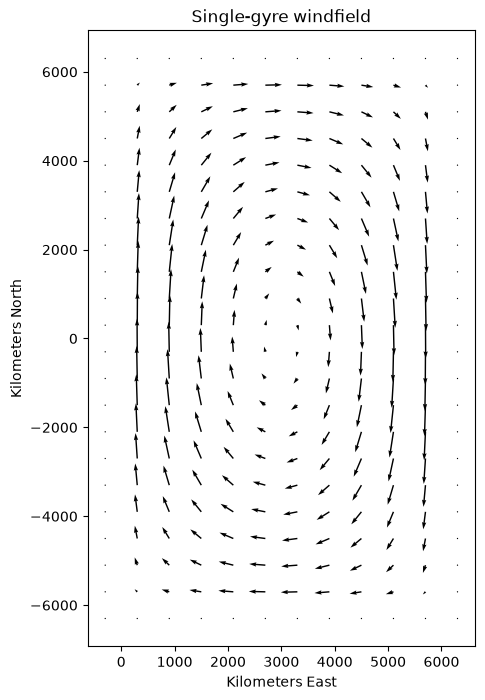

In [27]:
my_wind = windfield(my_grid, option="single_gyre")
plt.figure(figsize=(5, 8))
plt.quiver(my_grid.X / 1e3, my_grid.Y / 1e3, my_wind.u, my_wind.v)
plt.xlabel("Kilometers East")
plt.ylabel("Kilometers North")
plt.title("Single-gyre windfield");

Before running the gyre we check the numerical scheme. Forward Euler with centered differences is only conditionally stable. The **diffusion number** $\mathrm{d} = \kappa\,\Delta t\,(1/\Delta x^{2} + 1/\Delta y^{2})$ must be below $1/2$, and the **grid P&eacute;clet number** $\mathrm{Pe} = |\vec{u}|\,\Delta x / \kappa$ should be below about $2$, otherwise the centered advection scheme produces spurious oscillations.

In [28]:
kappa = 3e4     # diffusivity [m2/s]
speed = np.sqrt(my_wind.u**2 + my_wind.v**2)
print(f"peak speed          = {speed.max()*100:.1f} cm/s")
print(f"diffusion number d  = {kappa * deltat * (1/my_grid.deltax**2 + 1/my_grid.deltay**2):.3f}   (must be < 0.5)")
print(f"grid Peclet number  = {speed.max() * my_grid.deltax / kappa:.2f}   (should be < 2)")

peak speed          = 5.1 cm/s
diffusion number d  = 0.007   (must be < 0.5)
grid Peclet number  = 1.02   (should be < 2)


In [29]:
my_temp = np.zeros((my_grid.grid.shape))
my_temp[8:13, :] = 1

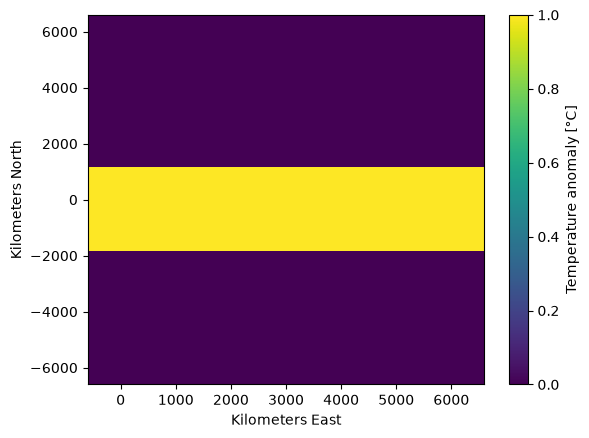

In [30]:
plt.pcolor(my_grid.xs / 1e3, my_grid.ys / 1e3, my_temp)
plt.colorbar(label = "Temperature anomaly [°C]")
plt.ylabel("Kilometers North")
plt.xlabel("Kilometers East");

Move the sliders to watch the band of warm water being carried round the basin by the gyre while diffusion smooths it. The stability check above used $\kappa = 3\times10^{4}$ m$^2$ s$^{-1}$. If you lower $\kappa$ to $10^{4}$ m$^2$ s$^{-1}$ the grid P&eacute;clet number rises to about 3, and the temperature develops small spurious over- and undershoots (values slightly below 0 or above 1) next to the sharp edges of the band.

In [31]:
interact(plot_func,
         temp = fixed(my_temp),
         deltat = fixed(deltat),
         windfield = fixed(my_wind),
         grid = fixed(my_grid),
         kappa = widgets.FloatSlider(description="kappa", value = 3e4, min=1e4, max = 1e5, step = 1e3, readout_format=".0f"),
         anomaly = widgets.Checkbox(description = "Anomaly", value=False),
         steps = widgets.IntSlider(description="Timesteps", value = 20, min = 1, max = 1000, step = 1));

interactive(children=(IntSlider(value=20, description='Timesteps', max=1000, min=1), FloatSlider(value=30000.0…

Optional: create two gyres! Replace $\sin(\pi(y+L)/2L)$ in the streamfunction by $\sin(\pi(y+L)/L)$, which gives two counter-rotating cells, and check that the temperature stays confined to the basin.

```{note} Sources
Adapted from the 2-D advection–diffusion / ocean-heat-transport lecture in the MIT
course
[*Introduction to Computational Thinking*](https://computationalthinking.mit.edu)
(Edelman, Sanders & van der Plas; climate lectures by Henri Drake &mdash; original
code, in Julia:
[simplEarth](https://github.com/hdrake/simplEarth/blob/master/4_ocean_heat_transport.jl)),
by way of the
[*Climate of the Ocean*](https://github.com/florianboergel/climateoftheocean) course,
for **CE524 Applied Hydroclimatology**.

Text under CC BY-SA 4.0; full attribution and per-lecture provenance in
[CREDITS.md](https://github.com/drvivekhydro/hydroclimatology/blob/main/CREDITS.md).
```
